In [1]:
import numpy as np
import liblie as ll
import matplotlib.pyplot as plt

In [2]:
class Simulator:
    def __init__(self, C0=None, cov_meas=np.eye(3,3), cov_evol=np.eye(3,3), rot_speed=.5):
        self.C = C0 if C0 is not None else ll.expm_so3(ll.wedge_so3(np.random.normal(size=3, scale=1)))
        self.Q = cov_evol
        self.R = cov_meas
        self.rot_speed = rot_speed

    def forward(self, dt=1):
        wk = np.random.normal(size=3, scale=1)
        wk = self.rot_speed/np.linalg.norm(wk)*wk
        self.C = ll.expm_so3(ll.wedge_so3(wk)*dt)@self.C
        
        wk_noisy = wk + np.random.multivariate_normal(mean=np.zeros((3)), cov=dt*self.Q)

        return wk_noisy
    
    def get_measurement(self):
        v = np.random.normal(size=3)
        y = self.C@v + np.random.multivariate_normal(mean=np.zeros((3)), cov=self.R)

        return v,y

    def get_true_rotation(self):
        return self.C
        

In [3]:
def dist_C(C1,C2):
    return np.linalg.norm(ll.vee_so3(ll.logm_so3(C1@C2.T)))

This cell defines the rotation-distance function using Lie algebra:

$$
d(C_1, C_2) = \|\operatorname{vee}(\log(C_1 C_2^T))\|_2
$$

Interpretation:
- `C1 @ C2.T` computes relative rotation.
- `logm_so3` maps that relative rotation back to tangent space (axis-angle style error).
- `vee_so3` converts skew-matrix form into a 3-vector.
- Euclidean norm gives a scalar angular discrepancy.

Why this is necessary: matrix element-wise differences are not geometrically meaningful on rotations. This metric gives a principled, group-aware error value.

In [4]:
#Set simulation parameters
#===========================
R = .1**2*np.eye(3,3)
Q = .001**2*np.eye(3,3)

N_it = 100 #number of iterations of the kalman filter
dt=.01 #s
#==========================
sim = Simulator(cov_meas = R, cov_evol = Q)


#set initial guess
#==========================
Ck = np.eye(3,3)
Pk = np.eye(3,3)
#===========================

error = np.zeros((N_it))




for i in range(N_it):

    omega_k = sim.forward(dt)

    v,y = sim.get_measurement()

    # Update the state (Rotation Matrix)
    Ck = ll.expm_so3(ll.wedge_so3(omega_k * dt)) @ Ck
    Fk = np.eye(3) 
    Pk = Fk @ Pk @ Fk.T + (dt**2) * Q


    # Predicted measurement
    y_pred = Ck @ v
    # residual
    z = y - y_pred
    # Jacobian H = -(Ck @ v)^wedge
    H = -ll.wedge_so3(Ck @ v)
    # Kalman Gain
    S = H @ Pk @ H.T + R
    K = Pk @ H.T @ np.linalg.inv(S)
    delta_phi = K @ z
    Ck = ll.expm_so3(ll.wedge_so3(delta_phi)) @ Ck
    

    # Update Covariance
    Pk = (np.eye(3) - K @ H) @ Pk
 
    #compute error
    error[i] = dist_C(Ck, sim.get_true_rotation())
 

This is the core estimation cell. It performs repeated predict/correct steps for `N_it` iterations.

### 1) Initialization
- Defines noise covariances `R` (measurement) and `Q` (evolution).
- Sets time step `dt` and number of iterations.
- Builds simulator instance.
- Initializes estimate `Ck`, covariance `Pk`, and error storage.

### 2) Per-iteration prediction
- Calls `sim.forward(dt)` to get noisy angular rate `omega_k`.
- Propagates estimate with exponential map: `Ck <- exp((omega_k dt)^) Ck`.
- Propagates covariance: `Pk <- Fk Pk Fk^T + dt^2 Q` with `Fk = I` (first-order approximation).

### 3) Per-iteration correction
- Gets vector measurement pair `(v, y)`.
- Predicts expected measurement `y_pred = Ck v`.
- Computes residual `z = y - y_pred`.
- Forms Jacobian `H = -(Ck v)^`.
- Computes innovation covariance `S`, Kalman gain `K`, correction `delta_phi = K z`.
- Updates orientation via Lie exponential: `Ck <- exp((delta_phi)^) Ck`.
- Updates covariance with standard linearized formula.

### 4) Monitoring
- Computes geometric estimation error versus truth each iteration and stores it.

Why this is necessary: this cell ties model, geometry, and filtering into one complete estimator. It is the main experimental engine and the reason all previous cells exist.

Text(0.5, 0, 'kalman iteration')

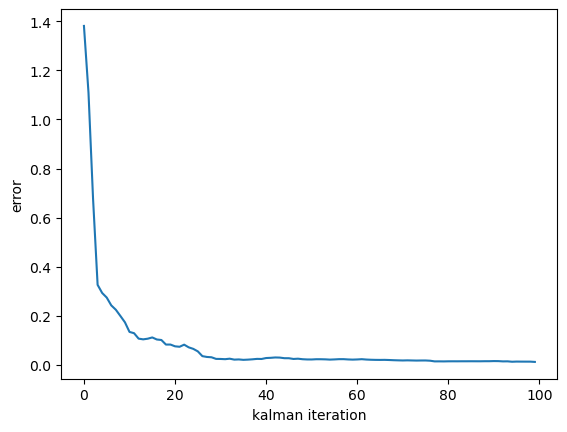

In [5]:
plt.plot(error)

# plt.legend()
plt.ylabel('error')
plt.xlabel('kalman iteration')

This final cell visualizes convergence by plotting `error` against iteration index.

Why this is necessary:
- It validates whether the filter actually improves the estimate over time.
- It helps diagnose poor tuning (e.g., unstable or plateauing error if `Q`/`R` are mismatched).
- It turns raw numeric output into an interpretable performance signal.